# 2-Read Turbine Output Data

### Imports

In [15]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np

from amtools.input_output import CaseReader

### Set data path and create case reader

In [2]:
# define path to example case
example_case_path = (pathlib.Path.cwd() / "example_case").resolve()

# create case reader object
case = CaseReader(example_case_path)

### Read in turbine output data & do some analysis

In [50]:
# read in thrust data from the file names "thrust".
# The combined time_dir will combine sample period. See
# examples 1 for more information
thrust = case.turbine_output("thrust", time_dir="combined")

# extract the time and thrust values from the file
t = thrust.time  # time
dt = thrust.dt  # timestep
T = thrust.data  # thrust

# read in axial force. This has a different shape of data compared to thrust
axial_force = case.turbine_output("axialForce", time_dir="combined")

# reader.data will have shape determined by the input file
print(
    f"Thrust has shape {T.shape}:\n\t{T.shape[0]} timesteps\n\t{T.shape[1]} thrust values"
)
print(
    f"Axial Force has shape {axial_force.data.shape}\n\t {axial_force.data.shape[0]} timesteps ({len(np.unique(axial_force.time))} times x {len(np.unique(axial_force.blade))} blades)\n\t {axial_force.data.shape[1]} blade stations\n"
)

# There are useful helps to get the individual blade data
axial_force_blade_2 = axial_force.get_using_blade_index(2)

# There are a number of other helper methods used such as crop the data
#  by a single blade to a certain window in time

# the underlying data structures are np.arrays which provide access to standard numpy methods
max_thrust = T.max()
min_thrust = T.min()
mean_thrust = T.mean()
var_thrust = T.var()

# or...
max_ax_force_at_bld_stat_1 = axial_force.data[:, 1].max()
min_ax_force_at_bld_stat_1 = axial_force.data[:, 1].min()
mean_ax_force_at_bld_stat_1 = axial_force.data[:, 1].mean()
var_ax_force_at_bld_stat_1 = axial_force.data[:, 1].var()

Thrust has shape (5, 1):
	5 timesteps
	1 thrust values
Axial Force has shape (15, 3)
	 15 timesteps (5 times x 3 blades)
	 3 blade stations



### Plotting Examples

We can use the reader to easily plot some quantities. For example, the rotor thrust against time

Text(0.5, 1.0, 'Rotor Thrust Against Time')

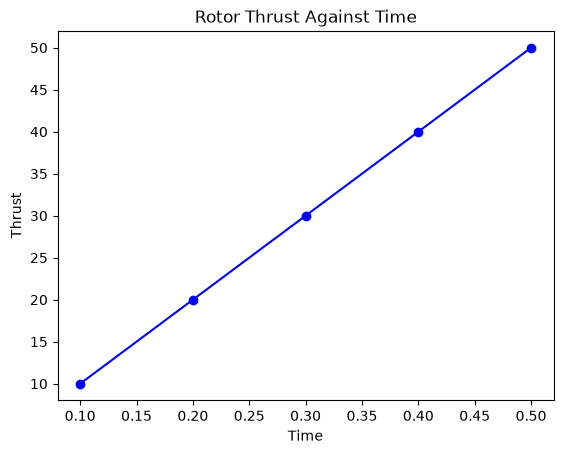

In [49]:
plt.figure()
plt.plot(thrust.time, thrust.data, "bo-")
plt.xlabel("Time")
plt.ylabel("Thrust")
plt.title("Rotor Thrust Against Time")

Or we could plot the axial force on blade station 1 for each blade against time

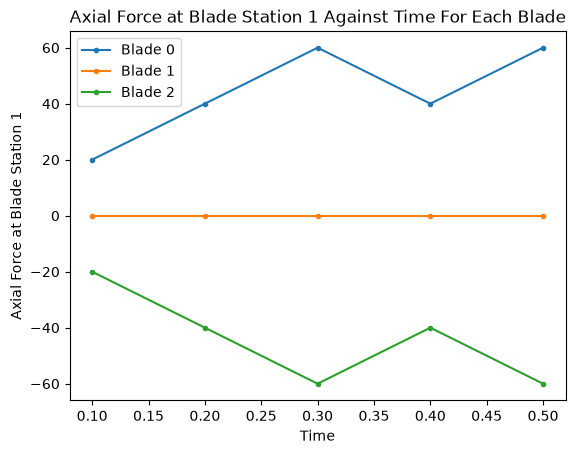

In [48]:
plt.figure()
for i in range(3):
    plt.plot(
        np.unique(axial_force.time),
        axial_force.get_using_blade_index(i)[:, 1],
        label=f"Blade {i}",
        marker=".",
    )
plt.xlabel("Time")
plt.ylabel("Axial Force at Blade Station 1")
plt.title("Axial Force at Blade Station 1 Against Time For Each Blade")
plt.legend()